<h1>Train — DenseNet-121</h1>

Trains and evaluates DenseNet-121 using the tuned hyperparameters from `ARCH_HYPERPARAMS["densenet121"]`, then saves its results and weights to disk for the results notebook.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']
Train: 1348 | Val: 323 | Test: 856


## Build dataloaders + class weights for this architecture

In [2]:
cfg = ARCH_HYPERPARAMS["densenet121"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"DenseNet-121: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders — its own (capped) batch size, and
# (for InceptionNet v3) its own image size.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

DenseNet-121: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 24)


## Define the model

In [3]:
# ---------------------------------------------------------
# Define the CNN (Transfer Learning with DenseNet-121)
# ---------------------------------------------------------
model = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
in_f = model.classifier.in_features
model.classifier = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the Bayesian-optimized step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[DenseNet-121] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[DenseNet-121] Epoch   1/100 | LR: 1.38e-04 | train loss 0.8513 acc 0.584 | val loss 0.5847 acc 0.712 *


[DenseNet-121] Epoch   2/100 | LR: 1.38e-04 | train loss 0.5574 acc 0.733 | val loss 0.5818 acc 0.752 *


[DenseNet-121] Epoch   3/100 | LR: 1.38e-04 | train loss 0.4912 acc 0.770 | val loss 0.4856 acc 0.799 *


[DenseNet-121] Epoch   4/100 | LR: 1.38e-04 | train loss 0.3885 acc 0.809 | val loss 0.6068 acc 0.768


...

[DenseNet-121] Epoch  11/100 | LR: 1.38e-04 | train loss 0.2336 acc 0.886 | val loss 0.4518 acc 0.854


[DenseNet-121] Epoch  12/100 | LR: 1.38e-04 | train loss 0.1703 acc 0.915 | val loss 0.4787 acc 0.861


[DenseNet-121] Epoch  13/100 | LR: 1.38e-04 | train loss 0.1275 acc 0.941 | val loss 0.6634 acc 0.811


[DenseNet-121] Epoch  14/100 | LR: 1.38e-04 | train loss 0.1562 acc 0.922 | val loss 0.4818 acc 0.836


[DenseNet-121] Epoch  15/100 | LR: 1.38e-04 | train loss 0.1222 acc 0.944 | val loss 0.6670 acc 0.796

[DenseNet-121] No val loss improvement for 10 epochs — stopping early at epoch 15.

[DenseNet-121] Restored best checkpoint (val loss = 0.4372)


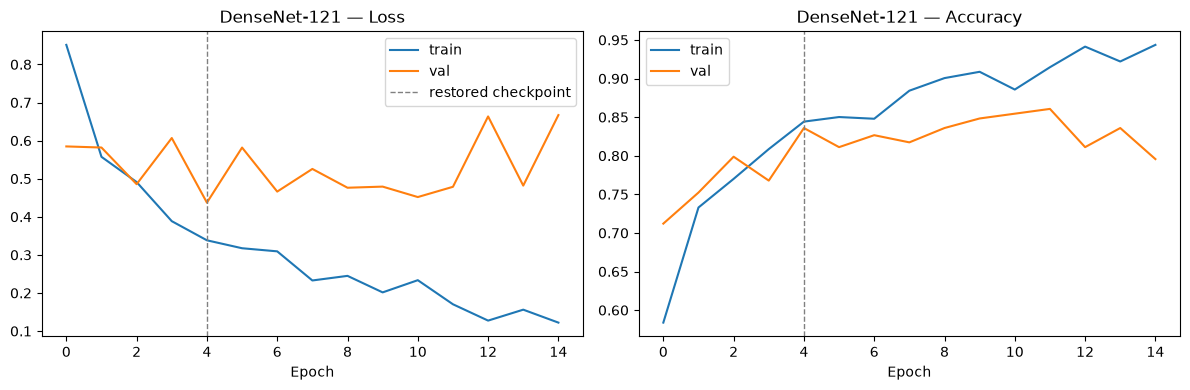

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "DenseNet-121", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "DenseNet-121")

## Evaluate on the test set

[DenseNet-121] Test accuracy: 0.785


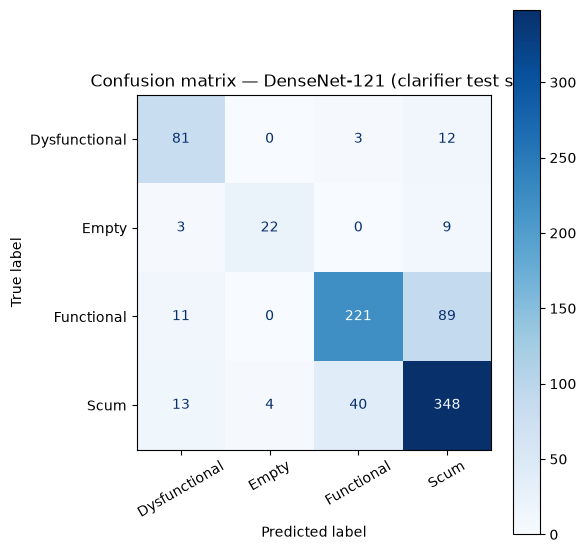

               precision    recall  f1-score   support

Dysfunctional      0.750     0.844     0.794        96
        Empty      0.846     0.647     0.733        34
   Functional      0.837     0.688     0.756       321
         Scum      0.760     0.859     0.806       405

     accuracy                          0.785       856
    macro avg      0.798     0.760     0.772       856
 weighted avg      0.791     0.785     0.783       856



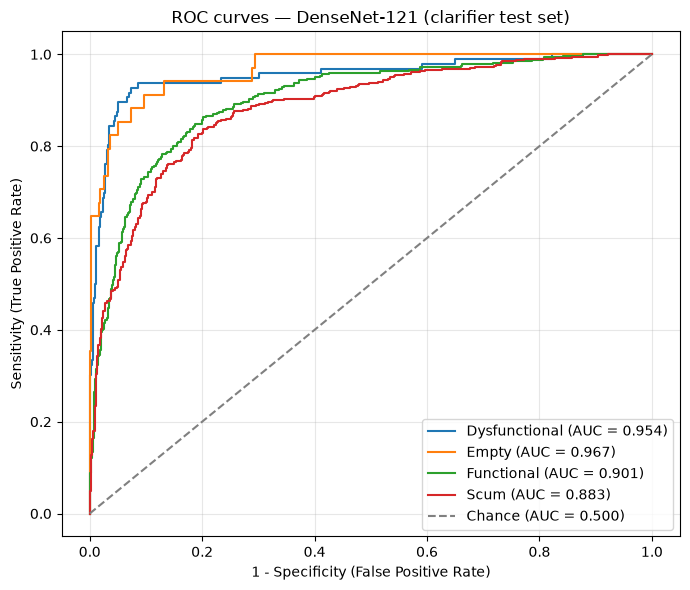

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.954
  Empty          : 0.967
  Functional     : 0.901
  Scum           : 0.883

Mean AUC (over 4/4 classes with test examples): 0.926


(np.float64(0.7850467289719626),
 {'Dysfunctional': 0.9542763157894737,
  'Empty': 0.9670459424645771,
  'Functional': 0.9011034442600518,
  'Scum': 0.8832060441816539})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "DenseNet-121", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

In [6]:
save_result("DenseNet-121", "densenet121")

Saved results to ../results/clarifier_aug/results_clarifier_densenet121_chronological.pkl
Saved model weights to ../models/pad/clarifier_densenet121_cnn.pt
